In [7]:
import io
import zipfile
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [8]:
# 1(a)
# Download and extract the dataset
url = "https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip"
response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("/content/CCPP")


file_path = "/content/CCPP/CCPP/Folds5x2_pp.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")

# Match the variable names used in the assignment
df = df.rename(columns={"AT": "T", "PE": "EP"})

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Shape: (9568, 5)
Columns: ['T', 'V', 'AP', 'RH', 'EP']


,T,V,AP,RH,EP
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


I downloaded the Combined Cycle Power Plant dataset from UCI and read Sheet1 of the Excel file. I renamed AT to T and PE to EP to match the notation in the assignment.

(9568, 5)
T     0
V     0
AP    0
RH    0
EP    0
dtype: int64


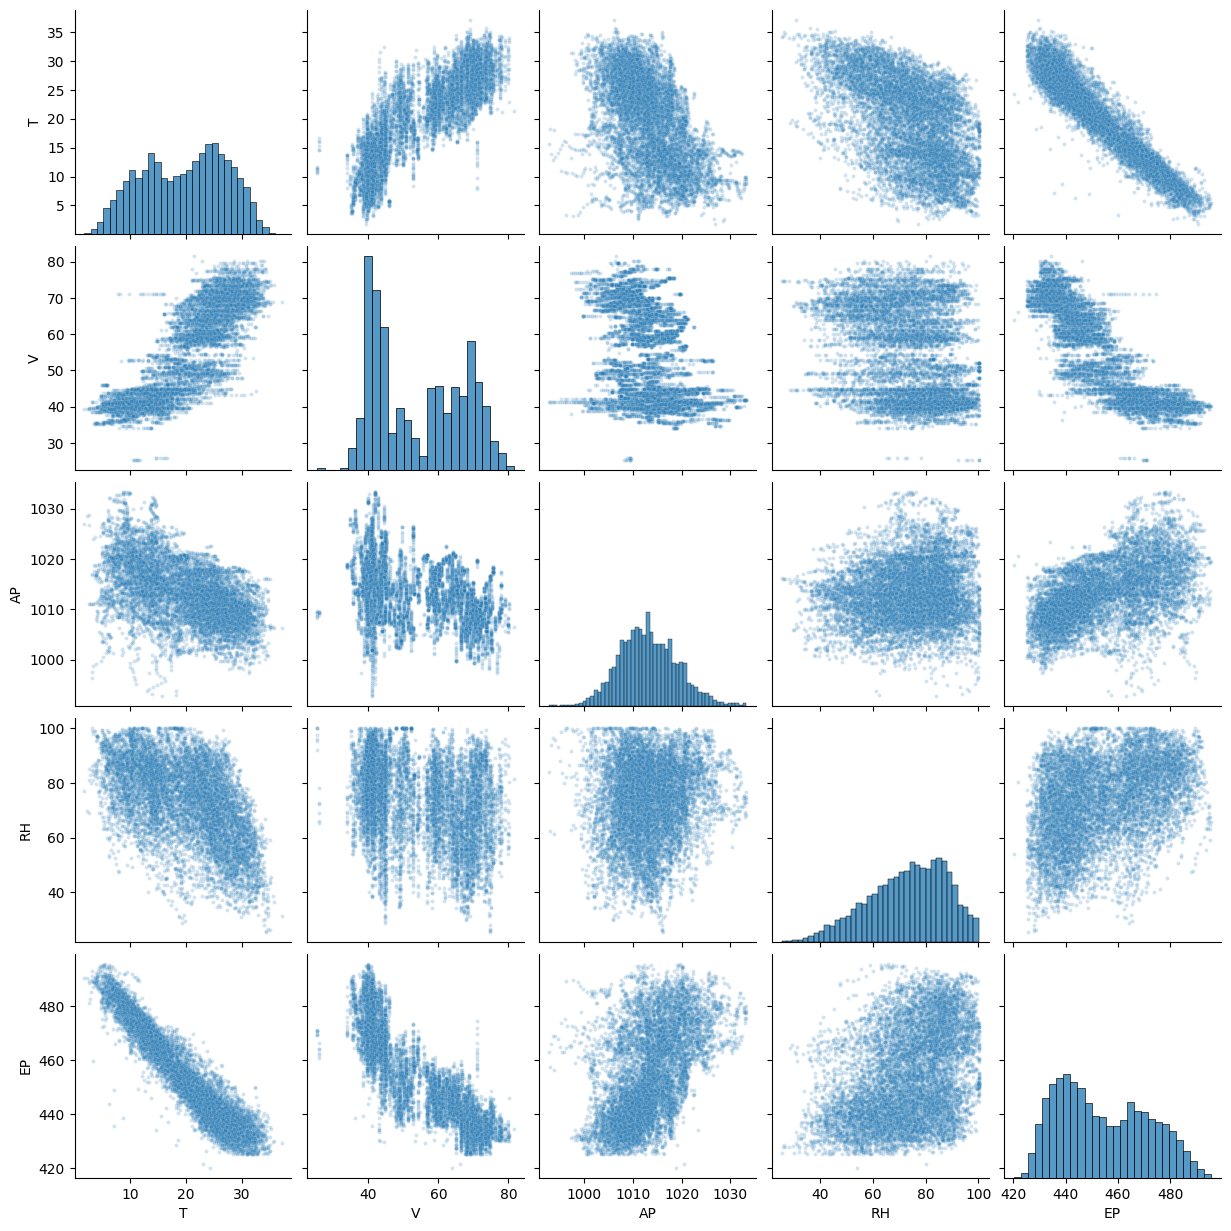

,T,V,AP,RH,EP
T,1.000,0.844,-0.508,-0.543,-0.948
V,0.844,1.000,-0.414,-0.312,-0.870
AP,-0.508,-0.414,1.000,0.100,0.518
RH,-0.543,-0.312,0.100,1.000,0.390
EP,-0.948,-0.870,0.518,0.390,1.000


,Mean,Median,Min,Max,Range,Q1,Q3,IQR
T,19.65,20.34,1.81,37.11,35.30,13.51,25.72,12.21
V,54.31,52.08,25.36,81.56,56.20,41.74,66.54,24.80
AP,1013.26,1012.94,992.89,1033.30,40.41,1009.10,1017.26,8.16
RH,73.31,74.97,25.56,100.16,74.60,63.33,84.83,21.50
EP,454.37,451.55,420.26,495.76,75.50,439.75,468.43,28.68


In [9]:
#1(b)
#i
print(df.shape)
print(df.isna().sum())

#ii
sns.pairplot(
    df,
    vars=["T", "V", "AP", "RH", "EP"],
    diag_kind="hist",
    plot_kws={"s": 8, "alpha": 0.2}
)
plt.show()

display(df.corr().round(3))

#iii
summary = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),
    "Min": df.min(),
    "Max": df.max(),
    "Range": df.max() - df.min(),
    "Q1": df.quantile(0.25),
    "Q3": df.quantile(0.75),
    "IQR": df.quantile(0.75) - df.quantile(0.25)
})

display(summary.round(2))

i:
The dataset has 9,568 rows and 5 columns. Each row contains hourly average measurements taken while the plant operated at full load. T, V, AP, and RH are the predictors, and EP is the electrical output to be predicted. There are no missing values.
ii:
EP has a strong negative relationship with T and a somewhat weaker negative relationship with V. Its relationships with AP and RH are positive but less clear. T and V are also strongly correlated with each other. Some scatterplots show curvature, so a straight-line model may not capture every relationship.
iii:
The table gives the requested statistics for each variable.

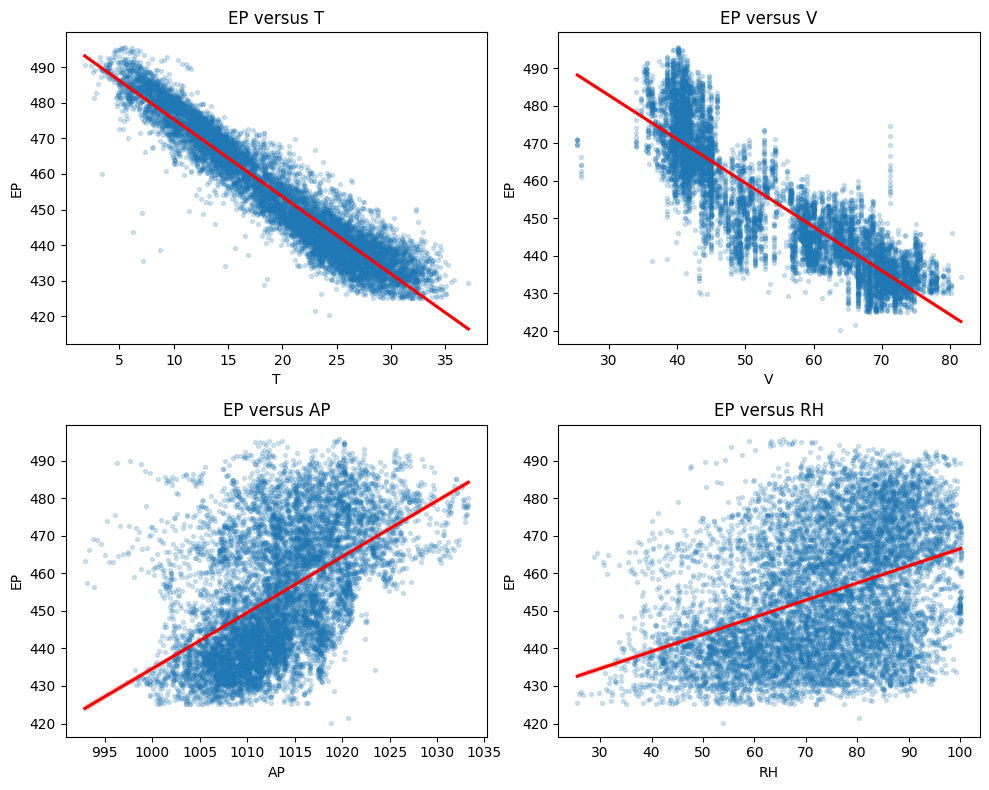

,Predictor,Intercept,Slope,p-value,R-squared
0,T,497.0341,-2.1713,0.0,0.8989
1,V,517.8015,-1.1681,0.0,0.7565
2,AP,-1055.2610,1.4899,0.0,0.2688
3,RH,420.9618,0.4557,0.0,0.1519


T number with |studentized residual| > 3: 42
V number with |studentized residual| > 3: 33
AP number with |studentized residual| > 3: 29
RH number with |studentized residual| > 3: 2


In [10]:
#1(c)
predictors = ["T", "V", "AP", "RH"]
simple_models = {}
simple_results = []

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for x, ax in zip(predictors, axes.flat):
    model = sm.OLS(df["EP"], sm.add_constant(df[[x]])).fit()
    simple_models[x] = model

    simple_results.append({
        "Predictor": x,
        "Intercept": model.params["const"],
        "Slope": model.params[x],
        "p-value": model.pvalues[x],
        "R-squared": model.rsquared
    })

    sns.regplot(
        data=df, x=x, y="EP", ax=ax,
        scatter_kws={"s": 8, "alpha": 0.2},
        line_kws={"color": "red"}
    )
    ax.set_title(f"EP versus {x}")

plt.tight_layout()
plt.show()
display(pd.DataFrame(simple_results).round(4))

for x, model in simple_models.items():
    residuals = model.get_influence().resid_studentized_internal
    print(x, "number with |studentized residual| > 3:",
          np.sum(np.abs(residuals) > 3))

All four simple-regression slopes are statistically significant at the 0.05 level. T and V have negative slopes, while AP and RH have positive slopes. T is the strongest single predictor, with R-squared equals 0.899. Its slope is approximately −2.17 MW per Celius. Some observations have large residuals, but I would inspect them rather than remove them automatically; a large residual may also indicate that a straight line does not fit well.

In [11]:
#1(d)
multiple_model = sm.OLS(
    df["EP"],
    sm.add_constant(df[predictors])
).fit()

print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     EP   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:56:12   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.0

The model fits in the equation:
EP=454.6093-1.9775T-0.2339V+0.0621AP-0.1581RH.
The model has R-squared =0.929. Each predictor has p < 0.05, so I reject the null hypothesis for all four predictors in the multiple regression.

In [ ]:
#1(e)
coef_comparison = pd.DataFrame({
    "Predictor": predictors,
    "Simple": [simple_models[x].params[x] for x in predictors],
    "Multiple": [multiple_model.params[x] for x in predictors]
})

display(coef_comparison.round(3))

plt.figure(figsize=(6, 5))
plt.scatter(coef_comparison["Simple"], coef_comparison["Multiple"])

for _, row in coef_comparison.iterrows():
    plt.annotate(
        row["Predictor"],
        (row["Simple"], row["Multiple"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.xlabel("Simple regression coefficient")
plt.ylabel("Multiple regression coefficient")
plt.title("Simple versus multiple regression coefficients")
plt.show()

The coefficients change when the other predictors are included. T remains strongly negative, but the coefficients for V and AP become much smaller. RH changes from a positive simple-regression slope to a negative multiple-regression coefficient. The predictors are correlated, so the marginal and adjusted relationships need not have the same sign or magnitude.

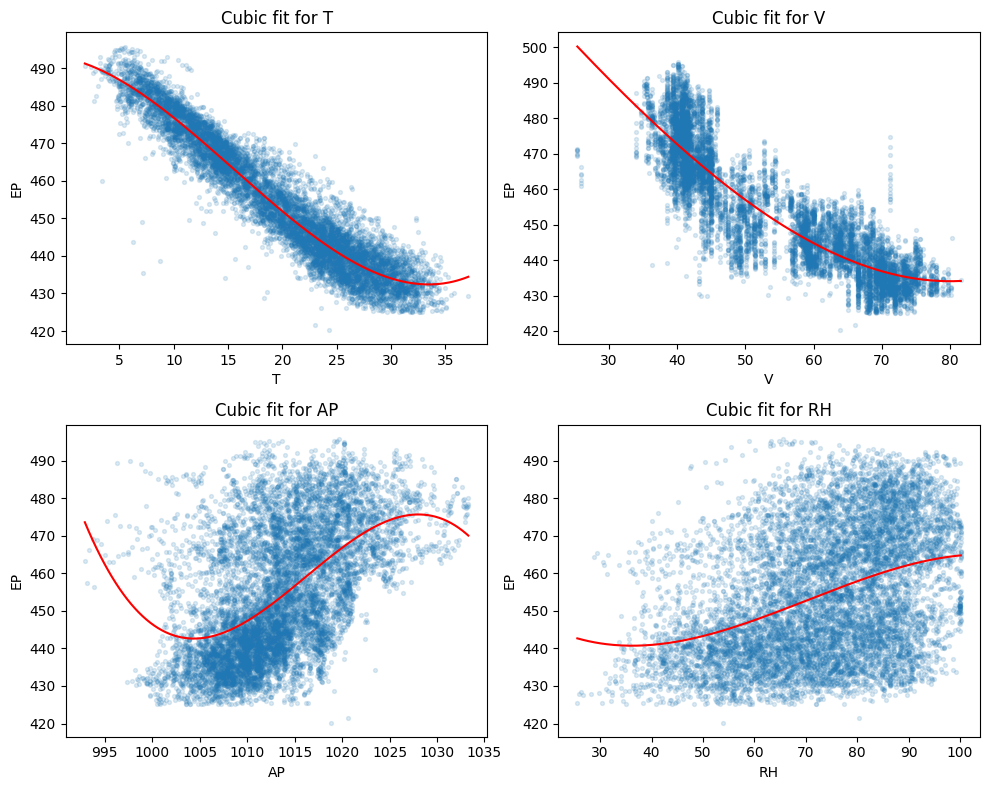

,Predictor,Linear R-squared,Cubic R-squared,F statistic,p-value
0,T,0.8989,0.9119,701.9673,0.0
1,V,0.7565,0.7750,393.3141,0.0
2,AP,0.2688,0.2975,195.8856,0.0
3,RH,0.1519,0.1537,10.1889,0.0


In [12]:
#1(f)
nonlinear_results = []
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for x, ax in zip(predictors, axes.flat):
    mean_x = df[x].mean()
    sd_x = df[x].std()
    z = (df[x] - mean_x) / sd_x

    cubic_X = pd.DataFrame({
        "z": z,
        "z2": z**2,
        "z3": z**3
    })

    cubic_model = sm.OLS(
        df["EP"], sm.add_constant(cubic_X)
    ).fit()

    f_stat, p_value, _ = cubic_model.compare_f_test(simple_models[x])

    nonlinear_results.append({
        "Predictor": x,
        "Linear R-squared": simple_models[x].rsquared,
        "Cubic R-squared": cubic_model.rsquared,
        "F statistic": f_stat,
        "p-value": p_value
    })

    grid = np.linspace(df[x].min(), df[x].max(), 200)
    grid_z = (grid - mean_x) / sd_x
    grid_X = pd.DataFrame({
        "const": 1,
        "z": grid_z,
        "z2": grid_z**2,
        "z3": grid_z**3
    })

    ax.scatter(df[x], df["EP"], s=8, alpha=0.15)
    ax.plot(grid, cubic_model.predict(grid_X), color="red")
    ax.set(xlabel=x, ylabel="EP", title=f"Cubic fit for {x}")

plt.tight_layout()
plt.show()
display(pd.DataFrame(nonlinear_results).round(4))

Comparing each cubic regression with its corresponding linear regression gives p < 0.05 for all four predictors. There is evidence of nonlinearity, although the size of the improvement varies. For T, R-squared increases from about 0.899 to 0.912. For RH, it increases only from about 0.152 to 0.154.

In [14]:
#1(g) Pairwise interactions
from itertools import combinations

interaction_X = df[predictors].copy()
interaction_terms = []

for a, b in combinations(predictors, 2):
    term = f"{a}:{b}"
    interaction_X[term] = df[a] * df[b]
    interaction_terms.append(term)

interaction_model = sm.OLS(
    df["EP"],
    sm.add_constant(interaction_X)
).fit()

display(pd.DataFrame({
    "Coefficient": interaction_model.params[interaction_terms],
    "p-value": interaction_model.pvalues[interaction_terms]
}).round(5))

print("R-squared:", interaction_model.rsquared)
print("Joint F-test:", interaction_model.compare_f_test(multiple_model))

,Coefficient,p-value
T:V,0.02097,0.00000
T:AP,0.00176,0.45205
T:RH,-0.00523,0.00000
V:AP,0.00681,0.00000
V:RH,0.00084,0.08619
AP:RH,-0.00161,0.03361


R-squared: 0.9363057529178327
Joint F-test: (np.float64(190.29858433473092), np.float64(8.0643630567226115e-230), np.float64(6.0))


At the 0.05 level, T:V, T:RH, V:AP, and AP:RH are significant. T:AP and V:RH are not. Including the interactions increases R-squared from about 0.929 to 0.936. The joint F-test also indicates that the six interaction terms improve the model as a group.

In [15]:
#1(h)
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

train, test = train_test_split(
    df, test_size=0.30, random_state=42
)

def make_features(data, center):
    centered = data[predictors] - center
    X = centered.copy()

    for x in predictors:
        X[f"{x}^2"] = centered[x]**2

    for a, b in combinations(predictors, 2):
        X[f"{a}:{b}"] = centered[a] * centered[b]

    return X

center = train[predictors].mean()
X_train = make_features(train, center)
X_test = make_features(test, center)

linear_model = sm.OLS(
    train["EP"],
    sm.add_constant(train[predictors], has_constant="add")
).fit()

full_model = sm.OLS(
    train["EP"],
    sm.add_constant(X_train, has_constant="add")
).fit()

In [16]:
terms = list(X_train.columns)

while True:
    current = sm.OLS(
        train["EP"],
        sm.add_constant(X_train[terms], has_constant="add")
    ).fit()

    removable = []

    for term in terms:
        if term in predictors:
            # Keep a main effect if any retained higher-order term uses it.
            needed = any(
                term in higher.replace("^2", "").split(":")
                for higher in terms
                if higher not in predictors
            )
            if needed:
                continue

        removable.append(term)

    if not removable:
        break

    worst = current.pvalues[removable].idxmax()

    if current.pvalues[worst] <= 0.05:
        break

    terms.remove(worst)

selected_model = sm.OLS(
    train["EP"],
    sm.add_constant(X_train[terms], has_constant="add")
).fit()

def model_errors(name, model, train_X, test_X):
    train_pred = model.predict(
        sm.add_constant(train_X, has_constant="add")
    )
    test_pred = model.predict(
        sm.add_constant(test_X, has_constant="add")
    )

    return {
        "Model": name,
        "Train MSE": mean_squared_error(train["EP"], train_pred),
        "Test MSE": mean_squared_error(test["EP"], test_pred)
    }

regression_results = pd.DataFrame([
    model_errors(
        "Linear", linear_model,
        train[predictors], test[predictors]
    ),
    model_errors(
        "Full quadratic + interactions", full_model,
        X_train, X_test
    ),
    model_errors(
        "Selected quadratic + interactions", selected_model,
        X_train[terms], X_test[terms]
    )
])

display(regression_results.round(3))
print("Selected terms:", terms)

,Model,Train MSE,Test MSE
0,Linear,20.581,21.240
1,Full quadratic + interactions,17.888,18.647
2,Selected quadratic + interactions,17.891,18.660


Selected terms: ['T', 'V', 'AP', 'RH', 'T^2', 'AP^2', 'RH^2', 'T:V', 'T:AP', 'T:RH', 'AP:RH']


The split contains 6,697 training and 2,871 test observations. The linear model has a test MSE of approximately 21.240. The full model with squared terms and interactions lowers test MSE to 18.647. After removing insignificant eligible terms, test MSE is approximately 18.660. Both expanded models improve on the linear model, while the shorter selected model performs almost the same as the full model.

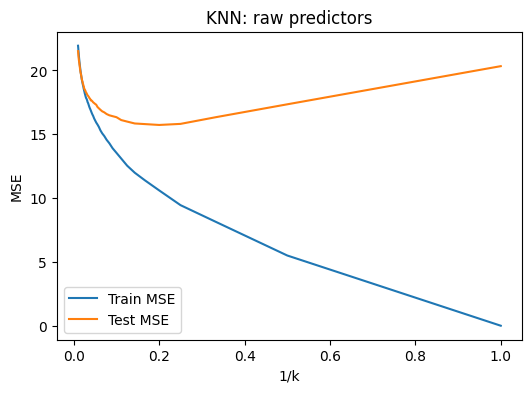

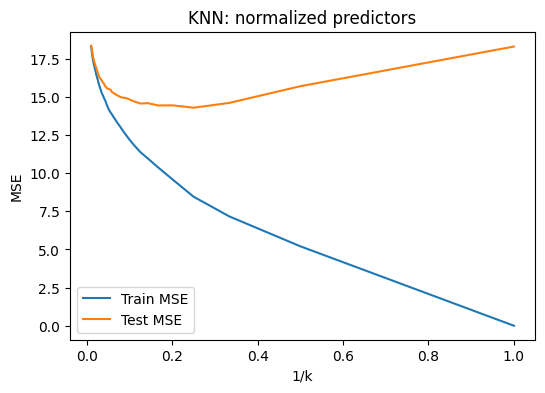

,Best k,CV MSE,Train MSE,Test MSE
Raw,5.0,17.007,10.601,15.727
Normalized,4.0,15.431,8.454,14.291


In [17]:
#1(i)
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler

X_train_raw = train[predictors].to_numpy()
X_test_raw = test[predictors].to_numpy()
y_train = train["EP"].to_numpy()
y_test = test["EP"].to_numpy()

cv = KFold(n_splits=5, shuffle=True, random_state=42)
knn_results = {}

for version in ["Raw", "Normalized"]:
    cv_mse = []

    # Select k using training data only.
    for k in range(1, 101):
        fold_mse = []

        for fit_idx, val_idx in cv.split(X_train_raw):
            X_fit = X_train_raw[fit_idx]
            X_val = X_train_raw[val_idx]

            if version == "Normalized":
                fold_scaler = MinMaxScaler().fit(X_fit)
                X_fit = fold_scaler.transform(X_fit)
                X_val = fold_scaler.transform(X_val)

            knn = KNeighborsRegressor(n_neighbors=k)
            knn.fit(X_fit, y_train[fit_idx])

            fold_mse.append(
                mean_squared_error(
                    y_train[val_idx],
                    knn.predict(X_val)
                )
            )

        cv_mse.append(np.mean(fold_mse))

    best_k = int(np.argmin(cv_mse) + 1)

    if version == "Normalized":
        scaler = MinMaxScaler().fit(X_train_raw)
        Xtr = scaler.transform(X_train_raw)
        Xte = scaler.transform(X_test_raw)
    else:
        Xtr = X_train_raw
        Xte = X_test_raw

    train_mse = []
    test_mse = []

    for k in range(1, 101):
        knn = KNeighborsRegressor(n_neighbors=k)
        knn.fit(Xtr, y_train)

        train_mse.append(
            mean_squared_error(y_train, knn.predict(Xtr))
        )
        test_mse.append(
            mean_squared_error(y_test, knn.predict(Xte))
        )

    knn_results[version] = {
        "Best k": best_k,
        "CV MSE": cv_mse[best_k - 1],
        "Train MSE": train_mse[best_k - 1],
        "Test MSE": test_mse[best_k - 1]
    }

    plt.figure(figsize=(6, 4))
    plt.plot(1 / np.arange(1, 101), train_mse, label="Train MSE")
    plt.plot(1 / np.arange(1, 101), test_mse, label="Test MSE")
    plt.xlabel("1/k")
    plt.ylabel("MSE")
    plt.title(f"KNN: {version.lower()} predictors")
    plt.legend()
    plt.show()

display(pd.DataFrame(knn_results).T.round(3))

Five-fold cross-validation selects k=5 for the raw predictors and k=4 for the normalized predictors. Their test MSEs are approximately 15.727 and 14.291, respectively. Normalization improves KNN performance on this split

The full quadratic regression has the smallest test MSE among the regression models (18.647). Raw KNN has a lower test MSE (15.727), and normalized KNN performs best (14.291). KNN may capture local patterns that the quadratic regression misses. On this test split, I would choose normalized KNN for prediction.

2. ISLR 2.4.1

(a) A flexible method would generally perform better when n is very large and p is small. There are enough observations to estimate a more complicated relationship.

(b) A flexible method would generally perform worse when p is very large and n is small. It can easily overfit the limited training data.

(c) A flexible method would generally perform better when the true relationship is highly nonlinear, because it can represent shapes that a simple model cannot.

(d) A flexible method would generally perform worse when the error variance is very high. It may fit random noise in the training data.

| Observation | Coordinates | Class | Distance to \((0,0,0)\) |
|---|---|---|---:|
| 1 | (0,3,0))| Red | (3) |
| 2 | (2,0,0) | Red | (2) |
| 3 | (0,1,3) | Red | (sqrt{10}) |
| 4 | (0,1,2) | Green | (sqrt{5}) |
| 5 | (-1,0,1) | Green | (sqrt{2}) |
| 6 | (1,1,1) | Red | (sqrt{3}) |

3. ISLR 2.4.7

(a) I calculated each distance using (d= sqrt{X_1^2+X_2^2+X_3^2}), as shown in the table.

(b) For (K=1), observation 5 is closest, so the prediction is Green.

(c) For (K=3), the closest observations are 5, 6, and 2. Two are Red, so the prediction is Red.

(d) A relatively small (K) would generally be preferable for a highly nonlinear Bayes decision boundary, because it follows local changes more closely.